# Lab 6
We will start of with the same setup as Lab 5 since they are very useful.

In [1]:
import lightkurve as lk #for getting light curves (in the format of astropy.timeseries)
import matplotlib.pyplot as plt #for plotting (lightkurve can also plot by using .plot() behind, but matplotlib is more flexible)
import pandas as pd #pandas is used for dataframe manipulation.
import numpy as np #numpy is used for numerical calculations.
plt.rcParams['figure.figsize']=[12,4]
plt.rcParams['figure.dpi']=300

c:\Users\tatap\miniconda3\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [ ]:
kiclist=pd.read_csv('KICID.csv') #read the file as dataframe.
def kicid(id): #A simple function to return the KIC ID of a star given its index in the kiclist dataframe to be used with lightkurve.
    return 'KIC '+str(kiclist['kepid'][id])
id=12 #Choose the 12th star to show what transit looks like.

In [20]:
# Quarter 10 in lab 5 is actually Quarter 11 due to the quarter starts from 1 instead of 0, so every quarter needs to add 1 to it.
searchtable=lk.search_lightcurve('KIC 6862328', mission='Kepler',quarter=11) # Search for light curves of the selected star.
t0=kiclist['koi_time0bk'][id] #t0 or time where the transit occurs.
period=kiclist['koi_period'][id] #period of the transit.
searchtable #it returns with a table of light curves from different quarters which is the first column.

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 11,2012,Kepler,1800,kplr006862328,0.0


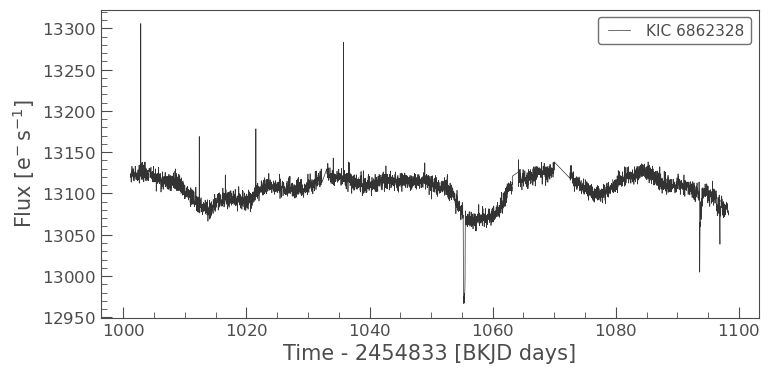

In [17]:
data=searchtable.download() #download all the light curves (slow but useful since some quarters might not have transit).
data.plot() #built-in plot function of lightkurve. It plots all the quarters in one figure, but it is not very flexible.
plt.show() #necessary since it will glitch if not included.

In [ ]:
def hasTransit(data,t0=t0,period=period): #check if the light curve has transit or not. It returns True if it has transit, otherwise False.
    tmin=data.time.value.min() #min time in the quarter.
    tmax=data.time.value.max() #max time in the quarter.
    tlist=data.time.value #list of time
    nmin=int((tmin-t0)//period+1) #min 
    nmax=int((tmax-t0)//period)
    for i in range(nmin,nmax+1):
        tt=t0+i*period #transit time
        if (tt>tmin) and (tt<tmax) and min(abs(tt-tlist))<0.1: #check if transit time is in the quarter and if it is in no data areas.
            return True
    return False

def vlines(data,t0=t0,period=period): #draw vertical lines at the transit times.
    tmin=data.time.value.min()
    tmax=data.time.value.max()
    nmin=int((tmin-t0)//period+1)
    nmax=int((tmax-t0)//period)
    for i in range(nmin,nmax+1):
        plt.axvline(x=t0+i*period,color='r',linestyle='--',linewidth=0.5)

def lcplot(tbl,t0=t0,period=period,id=id,customtxt=None): #built-in plot of lightkurve with some customization.
    tbl.plot(marker='o',markersize=0.5,linewidth=0.3)
    plt.title(kicid(id)+' '+str(customtxt))
    plt.xlabel('Time [BKJD days]')
    plt.ylabel('Flux [e-/s]')
    vlines(tbl,t0,period)
def 

Now, we will look for the variables that affects look-elsewhere effect. \
First, let's look at the shape of light curve at transit and at the imposter. (each datapoint are equally spaced by 30 minutes)

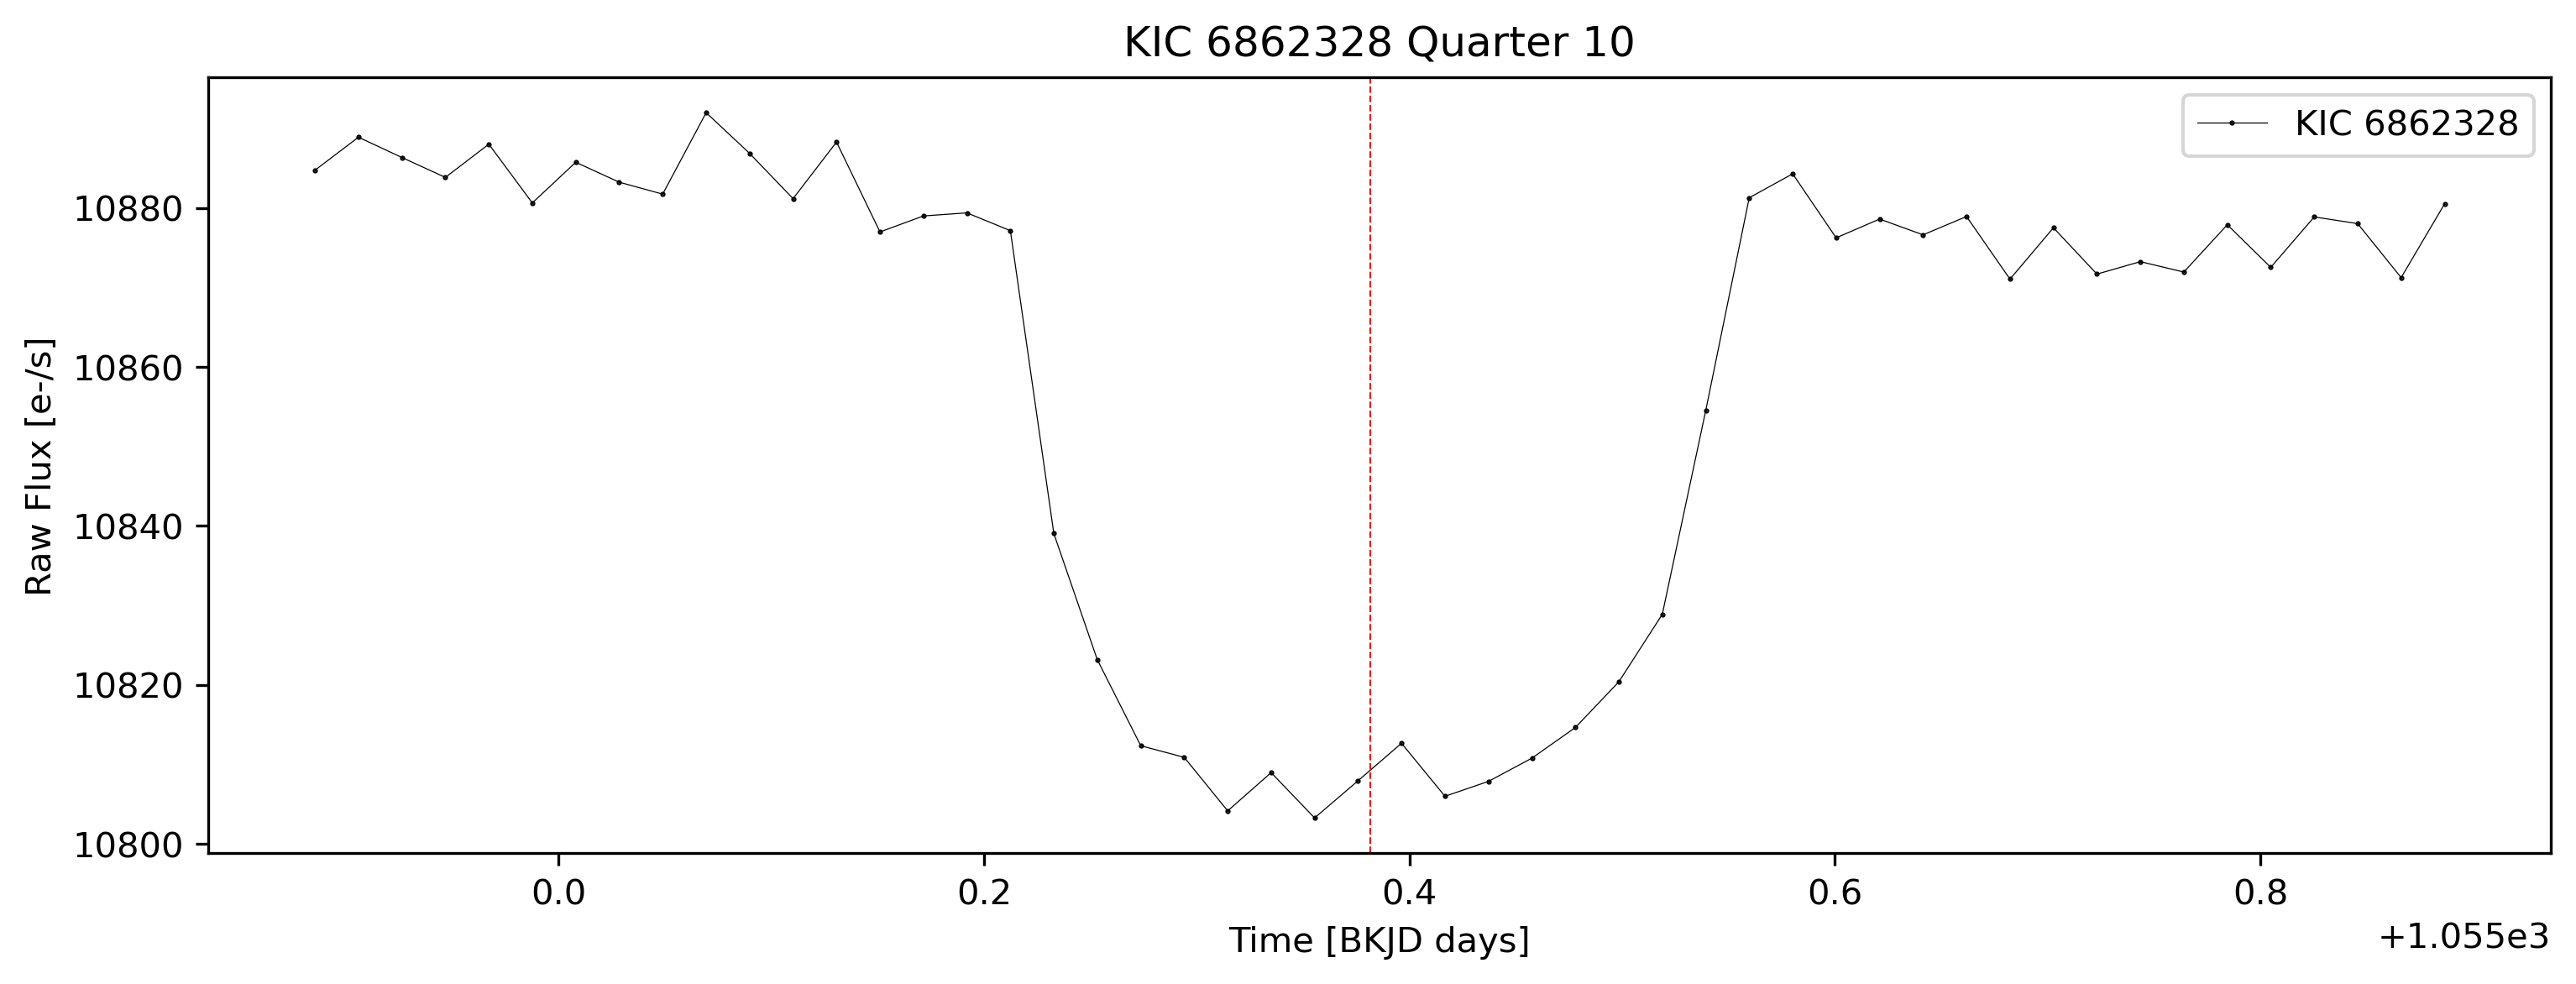

In [ ]:
plt.plot(data.time.value[2550:2600],data.sap_flux.value[2550:2600],color='k',marker='o',markersize=0.5,linewidth=0.3,label=kicid(id)) #plot raw data of quarter 10.
plt.title(kicid(id)+' '+str('Quarter 11'))
plt.xlabel('Time [BKJD days]')
plt.ylabel('Raw Flux [e-/s]')
vlines(data,t0,period)
plt.legend()
plt.show()

If we count the datapoints that are in the transit, we would get 16 (or around 8 hours). This means that the probability that the light curve would be dimmer due to look-elsewhere effect is going to be very small (16 times in a row is near impossible).

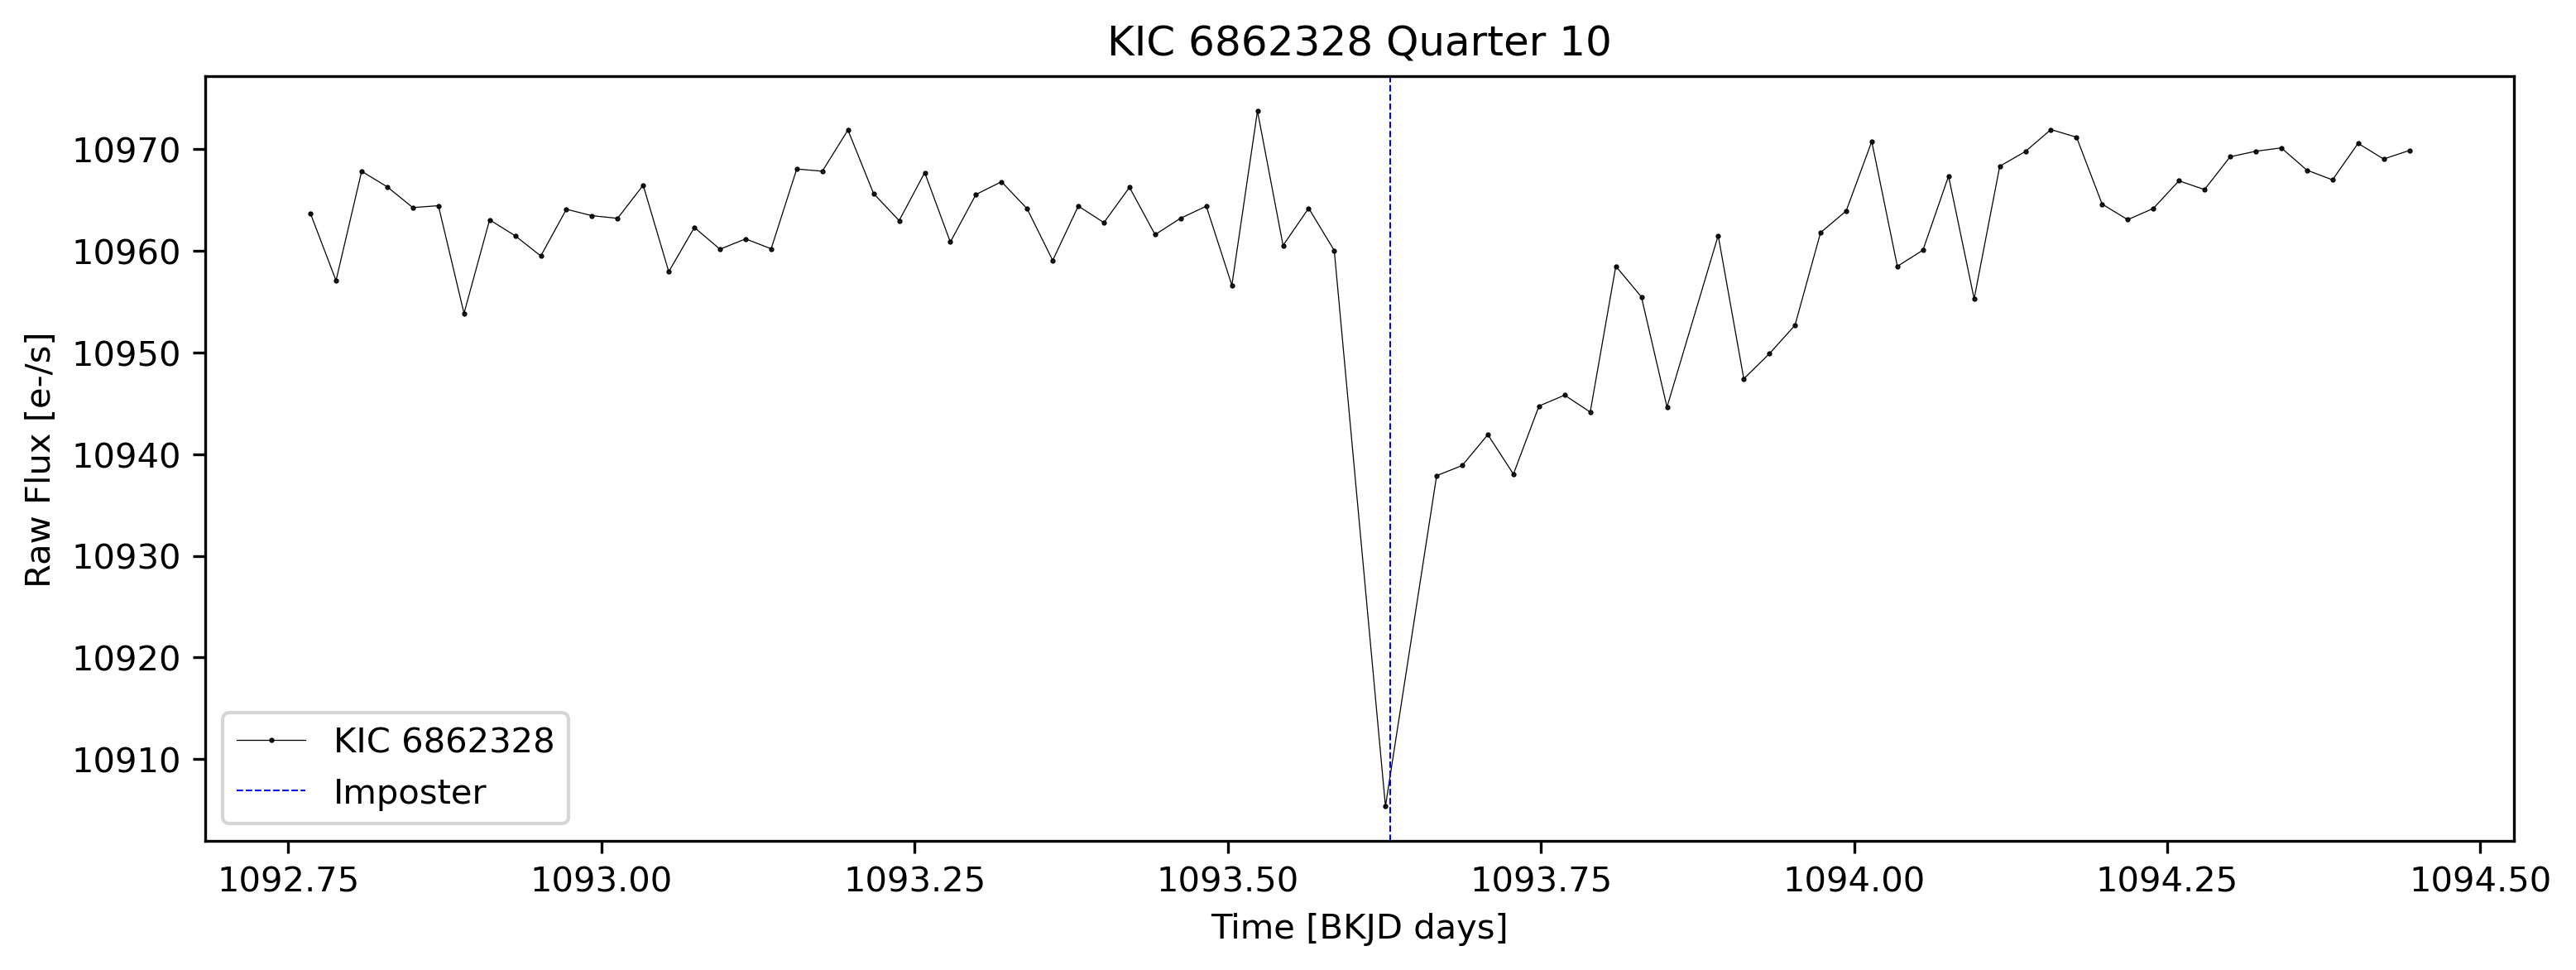

In [ ]:
plt.plot(data.time.value[4220:4300],data.sap_flux.value[4220:4300],color='k',marker='o',markersize=0.5,linewidth=0.3,label=kicid(id)) #plot raw data of quarter 10.
plt.title(kicid(id)+' '+str('Quarter 11'))
plt.xlabel('Time [BKJD days]')
plt.ylabel('Raw Flux [e-/s]')
plt.axvline(x=1093.63,color='b',linestyle='--',linewidth=0.5,label='Imposter') #draw a blue vertical line at the imposter.
plt.legend()
plt.show()

As we can see, the look-elsewhere effect would only make 1 dim datapoints, so the star lightcurves that are susceptible to look-elsewhere effect should have small transit time and small dimming. \
This means that we should be looking for the planets with small transit depth (koi_depth [ppm]) that has short transit time around their host stars (koi_duration [hours]).

In [24]:
kiclist[kiclist["koi_duration"]<1]

,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
2,11918099,K00780.02,NaN,CANDIDATE,CANDIDATE,0.993,0,0,0,0,...,-79.0,4.595,0.012,-0.064,0.765,0.055,-0.028,293.83331,50.230350,15.334
38,3447722,K01198.04,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,292.47971,38.514919,15.319
103,4932442,K01665.02,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,...,-217.0,4.415,0.053,-0.302,1.129,0.579,-0.121,294.17108,40.055168,14.042
128,11773328,K01906.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,0,...,-160.0,4.575,0.034,-0.136,0.809,0.169,-0.068,296.62347,49.979172,14.816
147,8624520,K01816.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,0,...,-157.0,4.623,0.066,-0.044,0.640,0.056,-0.056,291.68329,44.751640,15.408
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1843,7447895,K06878.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,0,...,-163.0,4.573,0.027,-0.153,0.830,0.174,-0.062,292.72079,43.076809,14.709
1850,10070479,K07282.01,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,...,-125.0,4.606,0.027,-0.027,0.725,0.065,-0.051,289.96161,47.080360,15.590
1931,9390228,K07934.01,NaN,CANDIDATE,CANDIDATE,0.943,0,0,0,0,...,-177.0,4.516,0.050,-0.200,0.891,0.274,-0.091,284.67227,45.973820,15.581
1940,8527297,K08157.01,NaN,CANDIDATE,CANDIDATE,0.638,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,301.66180,44.577499,14.010
